<a href="https://colab.research.google.com/github/shahad030/Final-Project--Bayan-bilingual-citizen-feedback/blob/main/Copy_of_Lab2_Transformer_Anatomy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2 — Anatomy of a Transformer

**SDA-AIE-211 | Bayan Capstone | Google Colab**

Run top-to-bottom. Comments explain the purpose of the code. Work in pairs; do not report targets as achieved unless your own run verifies them.

## What you will do (6 parts)
| Part | What | Your job |
|---|---|---|
| 0 | Load the cleaned Bayan data from Lab 1 | run |
| 1 | Attention function **(given)** and comparison with PyTorch | run + read |
| 2 | Multi-head attention **(given)**, comparison with PyTorch, parameter count | run + 1 TODO |
| 3 | Padding mask and causal mask on real Bayan sentences | 2 TODOs |
| 4 | Why long sentences are expensive | 1 TODO |
| 5 | Choose `MAX_LENGTH` for the project | 1 TODO |



## Outcomes
Implement scaled dot-product attention, multi-head attention, causal masking, and padding diagnostics, and **verify each one against PyTorch**.

## Part 0 — Setup and data from Lab 1
Lab 1 ended by saving `bayan_feedback_clean.csv`. We continue the project from that file.

In [ ]:
# ---- Step 0.1: imports and settings ----
import math, json
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(211)                       # same random numbers every run
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cpu


In [ ]:
# ---- Step 0.2: mount Drive and load the cleaned CSV from Lab 1 ----
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = Path('/content/drive/MyDrive/NATURAL LANGUAGE PROCESSING WITH TRANSFORMER/Data')

# Lab 1 may have saved to /content (lost if the session was reset), so we look in Drive first
candidates = [DATA_DIR / '/content/bayan_feedback_clean.csv', Path('/content/artifacts')]
CLEAN_CSV = next((p for p in candidates if p.exists()), None)
assert CLEAN_CSV is not None, 'Clean CSV not found. Re-run the last cell of Lab 1 first.'

feedback = pd.read_csv(CLEAN_CSV)
assert 'text_clean' in feedback.columns, 'Column text_clean is missing; re-run Lab 1.'
print('Loaded from:', CLEAN_CSV, '| shape:', feedback.shape)
display(feedback[['text_clean', 'language']].head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded from: /content/bayan_feedback_clean.csv | shape: (12000, 12)


,text_clean,language
0,"Honestly, The card payment went through yet I ...",en
1,Update: Stray cats are tearing open the rubbis...,en
2,للعلم، اضطررنا لطلب وايت لأن الصنابير جافة. أر...,ar
3,سؤال: كان التأمين المسترد مستحقا في نوفمبر الم...,ar
4,ملاحظة سريعة: الصفحة تتجمد في الخطوة الأخيرة. ...,ar


In [ ]:
# ---- Step 0.3: tokenizer + a tiny batch of 3 REAL sentences ----
from transformers import AutoTokenizer

CHECKPOINT = 'xlm-roberta-base'      # or the bilingual checkpoint you chose in Lab 1
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

# 200 random sentences -> keep the shortest, a middle one and the longest.
# Different lengths means the batch needs padding (we need that in Part 3).
pool = sorted(feedback['text_clean'].astype(str).sample(200, random_state=211).tolist(), key=len)
demo = [pool[0], pool[len(pool) // 2], pool[-1]]
for s in demo: print(len(s), '|', s)

batch = tokenizer(demo, padding=True, return_tensors='pt')   # padding=True adds [PAD] tokens
ids = batch['input_ids'].to(device)             # (3, T) token ids
am  = batch['attention_mask'].to(device)        # (3, T) 1 = real token, 0 = PAD
print('ids shape:', ids.shape)
print('attention_mask:')
print(am)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

26 | Plesae look into my case 😤
74 | The lights flicker every evening around 8 AM. Appreciate the quick help! 😊
169 | Good news: Stray cats are tearing open the rubbish because the bin is full. On top of that, the lights flicker every evening around 1 PM. Thank you, it was sorted out. !
ids shape: torch.Size([3, 49])
attention_mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1]])


## Part 1 — Attention (given) and comparison with PyTorch
The four steps from the lecture: **scores → scale → softmax → mix with V**.
Rule: apply the mask to the scores **before** softmax.

In [ ]:
# ---- Step 1.1: the attention function (GIVEN - read the comments) ----
def attention(Q, K, V, mask=None):
    # Q, K, V: (..., sequence_length, head_dimension)
    d_k = Q.shape[-1]

    # Step 1+2: scores = Q times K-transposed, divided by sqrt(d_k)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)

    # Mask BEFORE softmax: where mask == 0 put a very negative number -> weight ~ 0
    if mask is not None:
        scores = scores.masked_fill(mask == 0, torch.finfo(scores.dtype).min)

    # Step 3: softmax turns scores into weights; every row sums to 1
    weights = torch.softmax(scores, dim=-1)

    # Step 4: output = weighted sum of the values
    return weights @ V, weights

In [ ]:
# ---- Step 1.2: compare with PyTorch's official attention ----
# shape: (batch=1, heads=2, tokens=4, head_dim=8)
Q = torch.randn(1, 2, 4, 8, device=device)
K = torch.randn(1, 2, 4, 8, device=device)
V = torch.randn(1, 2, 4, 8, device=device)

out, w = attention(Q, K, V)                       # our version
ref = F.scaled_dot_product_attention(Q, K, V)     # PyTorch version

print('Same output as PyTorch? ->', torch.allclose(out, ref, atol=1e-5))     # Expected: True
print('Every row sums to 1?    ->', torch.allclose(w.sum(-1), torch.ones_like(w.sum(-1)), atol=1e-5))  # Expected: True
assert torch.allclose(out, ref, atol=1e-5)

print('Attention matrix of head 0 (rows = tokens looking, columns = tokens looked at):')
print(w[0, 0].detach().cpu().numpy().round(2))

Same output as PyTorch? -> True
Every row sums to 1?    -> True
Attention matrix of head 0 (rows = tokens looking, columns = tokens looked at):
[[0.13 0.16 0.44 0.27]
 [0.26 0.18 0.3  0.25]
 [0.43 0.22 0.03 0.32]
 [0.22 0.73 0.01 0.03]]


In [ ]:
# ---- Step 1.3: why divide by sqrt(d_k)? ----
# Without scaling, dot products grow when the dimension grows -> softmax becomes too "sharp".
for d in [8, 64, 512]: #Dimension of the Key/Query Vectors
    q = torch.randn(1000, d); k = torch.randn(1000, d)
    raw = (q * k).sum(-1)                               # dot products
    print(f'd={d:4d} | spread without scaling = {raw.std():6.2f} | with scaling = {(raw / math.sqrt(d)).std():.2f}')
# Expected: the "without" column grows with d, the "with" column stays near 1

d=   8 | spread without scaling =   2.78 | with scaling = 0.98
d=  64 | spread without scaling =   7.80 | with scaling = 0.97
d= 512 | spread without scaling =  21.50 | with scaling = 0.95


## Part 2 — Multi-head attention (given), comparison with PyTorch, parameter count
Several small attention "heads" look at the sentence in parallel. Their outputs are joined and mixed by one linear layer.

In [ ]:
# ---- Step 2.1: multi-head attention (GIVEN - read the comments) ----
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model=32, n_heads=4):
        super().__init__()
        assert d_model % n_heads == 0, 'd_model must be divisible by n_heads'
        self.h = n_heads                     # number of heads
        self.d = d_model // n_heads          # size of each head
        self.qkv = nn.Linear(d_model, 3 * d_model)   # one layer makes Q, K and V together
        self.proj = nn.Linear(d_model, d_model)      # final mixing layer

    def forward(self, x, mask=None):
        B, T, D = x.shape                                  # batch, tokens, d_model
        q, k, v = self.qkv(x).chunk(3, dim=-1)            # 3 tensors of (B, T, D)
        # (B, T, D) -> (B, heads, T, head_dim): each head gets its own slice
        split = lambda z: z.reshape(B, T, self.h, self.d).transpose(1, 2)
        y, weights = attention(split(q), split(k), split(v), mask)
        y = y.transpose(1, 2).reshape(B, T, D)            # join the heads back
        return self.proj(y), weights

m = MultiHeadAttention().to(device)
x_test = torch.randn(2, 5, 32, device=device)
y_test, _ = m(x_test)
print('input:', x_test.shape, '| output:', y_test.shape)      # Expected: same shape
assert y_test.shape == x_test.shape

input: torch.Size([2, 5, 32]) | output: torch.Size([2, 5, 32])


In [ ]:
# ---- Step 2.2: compare with PyTorch's nn.MultiheadAttention ----
# PyTorch has the same layers inside, so we copy OUR weights into a PyTorch twin.
# If both give the same output, our implementation is correct.
def pytorch_twin(model):
    twin = nn.MultiheadAttention(model.proj.in_features, model.h, batch_first=True).to(device)
    with torch.no_grad():
        twin.in_proj_weight.copy_(model.qkv.weight);  twin.in_proj_bias.copy_(model.qkv.bias)
        twin.out_proj.weight.copy_(model.proj.weight); twin.out_proj.bias.copy_(model.proj.bias)
    return twin.eval()

twin = pytorch_twin(m)
with torch.no_grad():
    y_ours, w_ours = m(x_test)
    y_pt, w_pt = twin(x_test, x_test, x_test, need_weights=True, average_attn_weights=False)

print('Same output as PyTorch?  ->', torch.allclose(y_ours, y_pt, atol=1e-5))    # Expected: True
print('Same weights as PyTorch? ->', torch.allclose(w_ours, w_pt, atol=1e-5))    # Expected: True
assert torch.allclose(y_ours, y_pt, atol=1e-5) and torch.allclose(w_ours, w_pt, atol=1e-5)

Same output as PyTorch?  -> True
Same weights as PyTorch? -> True


In [ ]:
# ---- Step 2.3: count the parameters ----
n_params = sum(p.numel() for p in m.parameters())
print('Parameters counted by PyTorch:', n_params)

# qkv : d x 3d weights + 3d biases = 3d^2 + 3d
# proj: d x d  weights +  d biases =  d^2 +  d      -> total = 4d^2 + 4d
d_model = 32
expected = 4 * d_model**2 + 4 * d_model          # = 4224
assert expected == n_params, f'Your formula gives {expected}, the model has {n_params}'

# More heads does NOT add parameters: we only SPLIT the same d_model into smaller pieces.
# The last column checks every version against PyTorch again.
for h in [1, 2, 4, 8]:
    mh = MultiHeadAttention(32, h).to(device)
    with torch.no_grad():
        same = torch.allclose(mh(x_test)[0], pytorch_twin(mh)(x_test, x_test, x_test)[0], atol=1e-5)
    print(f'heads={h} | parameters={sum(p.numel() for p in mh.parameters())} | same as PyTorch: {same}')

Parameters counted by PyTorch: 4224
heads=1 | parameters=4224 | same as PyTorch: True
heads=2 | parameters=4224 | same as PyTorch: True
heads=4 | parameters=4224 | same as PyTorch: True
heads=8 | parameters=4224 | same as PyTorch: True


## Part 3 — Padding mask and causal mask
* **Padding mask** (encoder and decoder): never attend to `[PAD]` tokens.
* **Causal mask** (decoder only): a token may not look at future tokens.

Both are matrices of 1 (allowed) and 0 (blocked), applied to the scores before softmax.

In [ ]:
# ---- Step 3.1: a tiny numeric example - why padding must be masked ----
# 6 positions, the last two are PAD (valid = 0)
scores = torch.tensor([[2., 1., .5, .2, 1.8, 1.5]])
valid  = torch.tensor([[1, 1, 1, 1, 0, 0]])
plain  = torch.softmax(scores, -1)                                   # PAD gets weight!
masked = torch.softmax(scores.masked_fill(valid == 0, -1e9), -1)     # PAD gets ~0
print('PAD mass without mask:', round(plain[0, 4:].sum().item(), 3), '| with mask:', masked[0, 4:].sum().item())
assert masked[0, 4:].sum() < .01

PAD mass without mask: 0.448 | with mask: 0.0


In [ ]:
# ---- Step 3.2: the two masks ----
def causal_mask(T):
    # lower triangle of ones: token i can see tokens 0..i only. Shape (1, 1, T, T) to broadcast.
    return torch.tril(torch.ones(T, T, device=device)).view(1, 1, T, T)

def padding_mask(attention_mask):
    # attention_mask: (B, T), 1 = real token, 0 = PAD  ->  (B, 1, 1, T) to broadcast over heads and queries
    return attention_mask[:, None, None, :]

print(causal_mask(4)[0, 0])       # 1s on and below the diagonal, 0s above
print(padding_mask(am).shape)     # (3, 1, 1, T)

tensor([[1., 0., 0., 0.],
        [1., 1., 0., 0.],
        [1., 1., 1., 0.],
        [1., 1., 1., 1.]])
torch.Size([3, 1, 1, 49])


In [ ]:
# ---- Step 3.3: test both masks on REAL Bayan sentences, and compare with PyTorch ----
T = ids.shape[1]
emb = nn.Embedding(len(tokenizer), 32).to(device)     # random embeddings (nothing is trained in this lab)
x = emb(ids)                                          # (3, T, 32)
mha = MultiHeadAttention(32, 4).to(device)
twin = pytorch_twin(mha)                              # PyTorch copy with the same weights

with torch.no_grad():
    y_none,   w_none   = mha(x)                              # no mask
    y_pad,    w_pad    = mha(x, padding_mask(am))            # our padding mask
    y_causal, w_causal = mha(x, causal_mask(T))              # our causal mask
    # PyTorch versions (note: PyTorch uses True = BLOCKED)
    y_pt_pad, _ = twin(x, x, x, key_padding_mask=(am == 0), need_weights=True, average_attn_weights=False)
    future = torch.triu(torch.ones(T, T, dtype=torch.bool, device=device), 1)
    y_pt_causal, _ = twin(x, x, x, attn_mask=future, need_weights=True, average_attn_weights=False)

# (a) How much attention goes to PAD positions?
pad_keys = (am == 0)[:, None, None, :].float()        # 1 where the key is a PAD token
print('attention on PAD, no mask     :', round((w_none * pad_keys).sum(-1).mean().item(), 4))   # Expected: bigger than 0
print('attention on PAD, padding mask:', (w_pad * pad_keys).sum(-1).mean().item())             # Expected: 0
assert (w_pad * pad_keys).sum() < 1e-6, 'padding mask is not working'

# (b) Causal: everything above the diagonal (the future) must be 0
print('attention on the future, causal mask:', w_causal.triu(1).sum().item())                  # Expected: 0
assert w_causal.triu(1).sum() < 1e-6, "causal mask is not working"

# (c) Same result as PyTorch? (compare real tokens only, PAD outputs do not matter)
keep = am.bool()
print('padding mask same as PyTorch:', torch.allclose(y_pad[keep], y_pt_pad[keep], atol=1e-5))   # Expected: True
print('causal mask  same as PyTorch:', torch.allclose(y_causal, y_pt_causal, atol=1e-5))         # Expected: True

attention on PAD, no mask     : 0.426
attention on PAD, padding mask: 0.0
attention on the future, causal mask: 0.0
padding mask same as PyTorch: True
causal mask  same as PyTorch: True


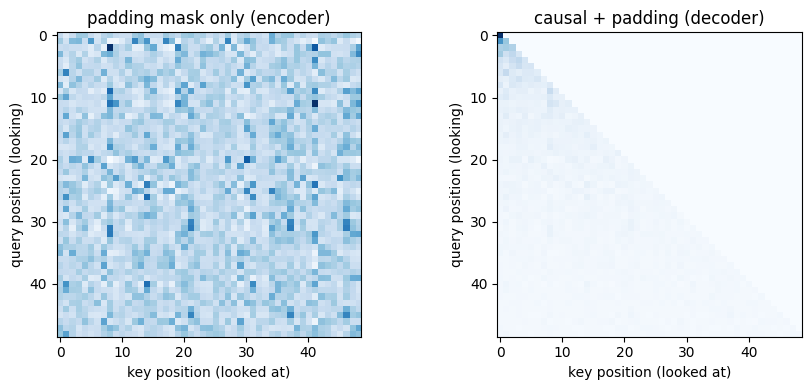

In [ ]:
# ---- Step 3.4: picture - padding mask only (encoder) vs causal + padding (decoder) ----
i = 2                                    # the longest sentence
n = int(am[i].sum())                     # number of real tokens (we do not plot PAD)
with torch.no_grad():
    _, w_both = mha(x, causal_mask(T) * padding_mask(am))   # a decoder uses BOTH masks together

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, w, title in zip(ax, [w_pad, w_both], ['padding mask only (encoder)', 'causal + padding (decoder)']):
    a.imshow(w[i, 0, :n, :n].cpu().numpy(), cmap='Blues')
    a.set_title(title); a.set_xlabel('key position (looked at)'); a.set_ylabel('query position (looking)')
plt.tight_layout(); plt.show()
# Expected: left = full square, right = lower triangle only

In [ ]:
# ---- Step 3.5 (BONUS): a padding regression test ----
# The SAME sentence must give the SAME output alone and inside a padded batch, if the mask is correct.
# Sentence 0 is the shortest, so in the batch it is padded the most.
one = tokenizer(demo[0], return_tensors='pt')['input_ids'].to(device)    # (1, n0) no padding
n0 = one.shape[1]

with torch.no_grad():
    y_alone, _ = mha(emb(one))                          # sentence alone
    y_batch, _ = mha(x, padding_mask(am))               # batch WITH padding mask
    y_batch_nomask, _ = mha(x)                          # batch WITHOUT a mask

same_with_mask    = torch.allclose(y_alone[0], y_batch[0, :n0], atol=1e-5)
same_without_mask = torch.allclose(y_alone[0], y_batch_nomask[0, :n0], atol=1e-5)
print('same with mask   :', same_with_mask)       # True
print('same without mask:', same_without_mask)    # False -> padding changed the result!
assert same_with_mask and not same_without_mask

same with mask   : True
same without mask: False


## Part 4 — Why long sentences are expensive
Attention compares every token with every token, so one attention matrix has T × T entries per head.

In [ ]:
# ---- Step 4.1: size of the attention matrix ----
for T_ in [64, 128, 256, 512]:
    entries = T_ * T_                # T x T entries per head
    mb = entries * 4 / 1e6           # float32 = 4 bytes; MB per head per sentence
    print(f'T={T_:4d} | entries={entries:8d} | {mb:6.2f} MB per head per sentence')
# Doubling T multiplies the size by 4 (quadratic growth)

T=  64 | entries=    4096 |   0.02 MB per head per sentence
T= 128 | entries=   16384 |   0.07 MB per head per sentence
T= 256 | entries=   65536 |   0.26 MB per head per sentence
T= 512 | entries=  262144 |   1.05 MB per head per sentence


## Part 5 — Project step: choose `MAX_LENGTH`
Padding and truncation need a maximum length. Too small cuts sentences; too large wastes memory. We choose it from the **95th percentile** (p95) of real token lengths, the same idea as Lab 1.

In [ ]:
# ---- Step 5.1: token length of every cleaned sentence ----
lengths = np.array([len(t) for t in tokenizer(feedback['text_clean'].astype(str).tolist())['input_ids']])

# p95 per language: compare Arabic vs English like the fertility audit in Lab 1
p95_by_lang = {lang: np.percentile(lengths[(feedback['language'] == lang).values], 95)
               for lang in feedback['language'].unique()}
print('p95 by language:', p95_by_lang)

p95 by language: {'en': np.float64(42.0), 'ar': np.float64(42.0)}


In [ ]:
# ---- Step 5.2: choose MAX_LENGTH and save it ----
p95_all = np.percentile(lengths, 95)                 # 95% of sentences are this long or shorter
MAX_LENGTH = int(np.ceil(p95_all))                   # round UP so 95% fit without truncation
truncated_pct = 100 * (lengths > MAX_LENGTH).mean()  # % of sentences that would be cut

print('p95 all:', p95_all, '| MAX_LENGTH:', MAX_LENGTH, '| truncated %:', round(truncated_pct, 2))

# Save the config so Lab 3 can load it
config = {'checkpoint': CHECKPOINT, 'max_length': int(MAX_LENGTH), 'p95_all': float(p95_all),
          'p95_by_language': {k: float(v) for k, v in p95_by_lang.items()}}

target_path = DATA_DIR / 'lab2_config.json'
try:
    # Try to write to Google Drive first
    with open(target_path, 'w', encoding='utf-8') as f:
        json.dump(config, f, indent=2)
    print('Saved to Google Drive:', target_path)
except OSError as e:
    # Fallback to local /content folder if Drive is read-only
    fallback_path = Path('/content/lab2_config.json')
    with open(fallback_path, 'w', encoding='utf-8') as f:
        json.dump(config, f, indent=2)
    print(f'Google Drive write failed ({e}). Saved locally instead to: {fallback_path}')

p95 all: 42.0 | MAX_LENGTH: 42 | truncated %: 4.24
Google Drive write failed ([Errno 30] Read-only file system: '/content/drive/MyDrive/NATURAL LANGUAGE PROCESSING WITH TRANSFORMER/Data/lab2_config.json'). Saved locally instead to: /content/lab2_config.json


## Thinking challenges — suggested answers
1. **Double the sequence length:** the attention matrix has T × T entries, so doubling T makes it **4 times larger** (quadratic), per head and per sentence. This is why we cap the length with `MAX_LENGTH`.
2. **Remove the padding mask:** real tokens give some attention to `[PAD]`, so the output of a sentence **depends on how much padding** its batch happens to have. The bonus test shows it: same sentence, different result alone vs in a batch.
3. **Attention weight ≠ causation:** a high weight only says the model mixed that token's value into the output. Many heads and layers combine, and removing the token may change nothing. Weights are a hint, not an explanation.
4. **Encoder vs decoder for fixed-label routing:** an encoder reads the **whole** sentence in both directions and gives one representation to classify, so it is cheaper and usually more accurate for routing a complaint to one of a fixed set of labels. A decoder is built to **generate** text one token at a time.